# EE348: Knowledge Representation and Reasoning in AI
## Lab 6: Structural Knowledge Representation
**Class:** BSAI-2024A  
**Date:** 15-10-2026 | **Duration:** 3 Hours  
**Course Instructor:** Dr. Saqib Nawaz | **Lab Engineer:** Syed Muhammad Ali Musa  
**CLO 1:** Understand various knowledge representation formalisms and reasoning techniques.

---

### Executive Overview & Lab Objectives
This practical explores structured knowledge representations for automated reasoning in a university domain:
1. **Semantic Networks:** Directed labeled multigraphs representing entities, taxonomic classification (`is-a`), and individual membership (`instance-of`).
2. **Frames, Slots & Fillers:** Prototype class frames and individual instance frames with monotonic and non-monotonic default inheritance.
3. **Multiple Inheritance Conflicts:** Diagnosing Nixon-diamond style default ambiguities and enforcing explicit override policies.
4. **Scripts (Schank & Abelson):** Stereotypic episodic event structures with roles, props, entry conditions, ordered scenes, results, and exception handling.
5. **Bipartite Graphs & Characterization:** Set partitioning, 2-colorability, and cycle-parity verification (König's Theorem).
6. **Conceptual Graphs (John Sowa) to FOL:** Bipartite directed knowledge graphs (concept boxes vs. relation circles) and automated translation to Ground First-Order Logic facts.
7. **Integrated University Knowledge Demonstration:** Reusable consolidated verification suite and challenge problem on taxonomic path traversal.

## Environment Setup & Library Imports
We initialize `networkx` for multigraph and bipartite structures and `matplotlib` for clear visual models.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Ensure inline plotting and clean styling
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print(f"NetworkX version: {nx.__version__}")

NetworkX version: 3.6.1


## Task 1 — University Knowledge Base
We construct an explicit university domain model consisting of named entities, classes, courses, and directed relations.
Explicit relations differentiate taxonomic subsumption (`is-a`), individual membership (`instance-of`), and associative domain relations (`enrolled-in`, `taught-by`).

### Exercise 1.1:
- Add an explicit relation representing that `AI201` is taught by `DrAhmed`.
- Print all relations involving `DrAhmed` (both as source and target).
- Explain why a class and an instance are fundamentally different.

In [2]:
# Base entities, classes, and courses
people = {"Ali", "Sara", "DrAhmed"}
classes = {"Person", "Student", "Teacher", "Course"}
courses = {"CS101", "AI201"}

# Base relations provided in lab manual
relations = [
    ("Student", "is-a", "Person"),
    ("Teacher", "is-a", "Person"),
    ("Ali", "instance-of", "Student"),
    ("Sara", "instance-of", "Student"),
    ("DrAhmed", "instance-of", "Teacher"),
    ("CS101", "instance-of", "Course"),
    ("AI201", "instance-of", "Course"),
    ("Ali", "enrolled-in", "CS101"),
    ("Sara", "enrolled-in", "AI201"),
    ("CS101", "taught-by", "DrAhmed")
]

# Exercise 1.1: Add explicit relation representing that AI201 is taught by DrAhmed
relations.append(("AI201", "taught-by", "DrAhmed"))

print(f"Total explicit facts in knowledge base: {len(relations)}")
print("-" * 60)
print("Complete Knowledge Base Relations:")
for src, rel, tgt in relations:
    print(f"  ({src}) --[{rel}]--> ({tgt})")

print("-" * 60)
# Print all relations involving DrAhmed
print("All relations involving DrAhmed:")
drahmed_relations = [r for r in relations if r[0] == "DrAhmed" or r[2] == "DrAhmed"]
for src, rel, tgt in drahmed_relations:
    role = "Subject (Source)" if src == "DrAhmed" else "Object (Target)"
    print(f"  [{role}] ({src}) --[{rel}]--> ({tgt})")

Total explicit facts in knowledge base: 11
------------------------------------------------------------
Complete Knowledge Base Relations:
  (Student) --[is-a]--> (Person)
  (Teacher) --[is-a]--> (Person)
  (Ali) --[instance-of]--> (Student)
  (Sara) --[instance-of]--> (Student)
  (DrAhmed) --[instance-of]--> (Teacher)
  (CS101) --[instance-of]--> (Course)
  (AI201) --[instance-of]--> (Course)
  (Ali) --[enrolled-in]--> (CS101)
  (Sara) --[enrolled-in]--> (AI201)
  (CS101) --[taught-by]--> (DrAhmed)
  (AI201) --[taught-by]--> (DrAhmed)
------------------------------------------------------------
All relations involving DrAhmed:
  [Subject (Source)] (DrAhmed) --[instance-of]--> (Teacher)
  [Object (Target)] (CS101) --[taught-by]--> (DrAhmed)
  [Object (Target)] (AI201) --[taught-by]--> (DrAhmed)


### Task 1 — Conceptual Explanation: Difference Between a Class and an Instance
> **Conceptual Meaning:**  
> A **class** is an abstract category, general concept, or ontological type (e.g., `Person`, `Student`, `Teacher`, `Course`) that defines the prototype, shared attributes, schema slots, and general behavioral contracts for a group of entities.  
> An **instance** is a concrete, individual, ground entity occurring in the real world (e.g., `Ali`, `Sara`, `DrAhmed`, `CS101`) that belongs to a class and possesses specific, realized attribute values.  
> In knowledge representation graphs, classes are structured taxonomically via `is-a` (subclass) specialization links, whereas instances are linked to their respective classes via `instance-of` (individual membership) links. Classes are intensional specifications, whereas instances are extensional members.

## Task 2 — Semantic Networks: Directed Labeled Graph
A **Semantic Network** represents knowledge as a directed graph where vertices denote concepts or individual entities and edges denote binary semantic relationships.
Using NetworkX `MultiDiGraph` allows us to preserve multiple typed directed relations between the same pair of entities.

### Exercises:
- **Exercise 2.1:** Print all outgoing relations from `Ali`.
- **Exercise 2.2:** Write `has_relation(source, relation, target)` returning `True`/`False`, and test two positive and two negative queries.
- **Exercise 2.3:** Explain why direction matters for `CS101 taught-by DrAhmed` and why that does not imply `DrAhmed taught-by CS101`.

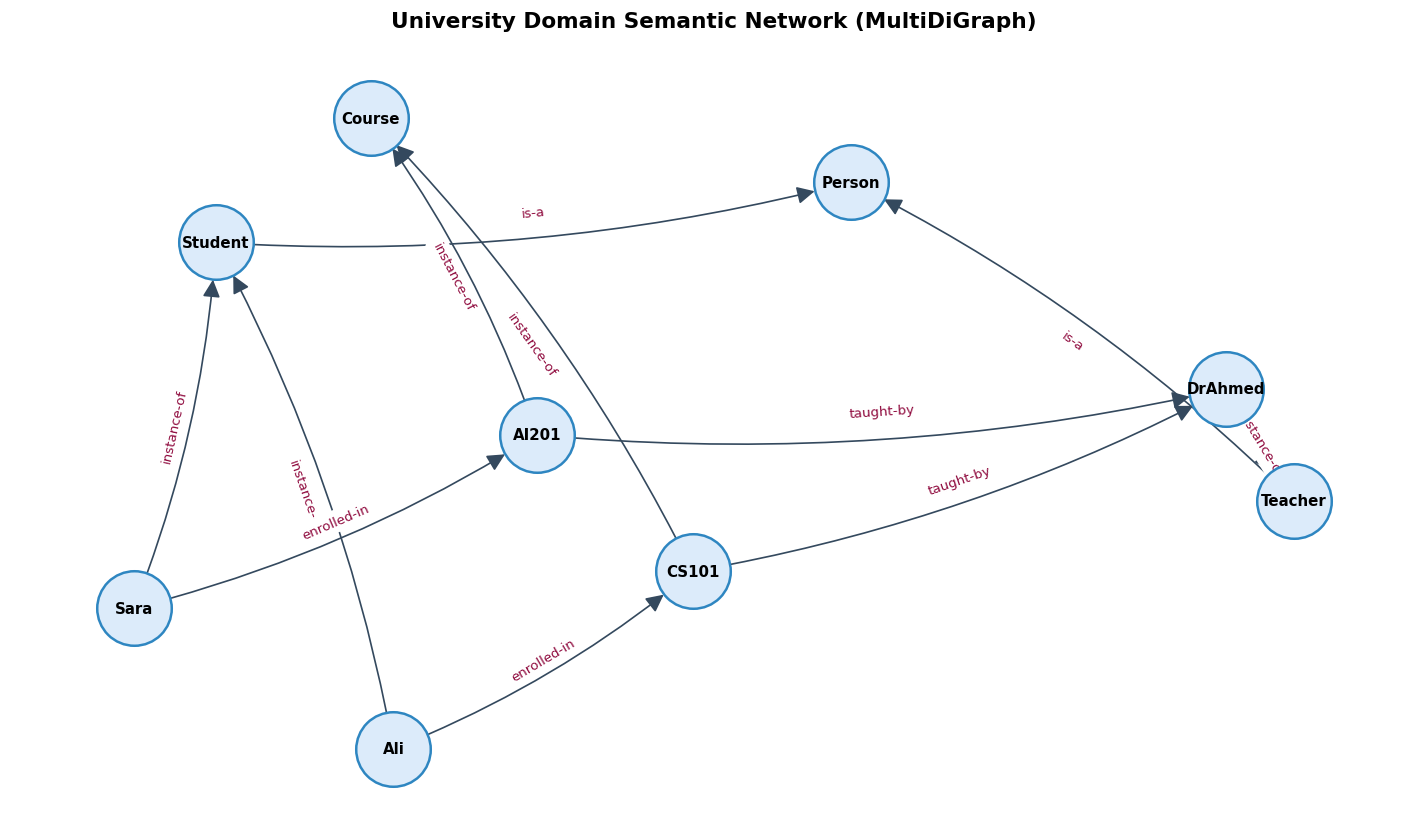

In [3]:
# Build MultiDiGraph
G = nx.MultiDiGraph()
for source, relation, target in relations:
    G.add_edge(source, target, relation=relation)

# Visual layout
pos = nx.spring_layout(G, seed=7, k=1.2)
plt.figure(figsize=(12, 7))

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='#DCEBFA', edgecolors='#2E86C1', linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

# Draw directed edges
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=22,
    node_size=2000,
    edge_color='#34495E',
    connectionstyle='arc3,rad=0.08'
)

# Draw edge labels
labels = {(u, v, k): d['relation'] for u, v, k, d in G.edges(keys=True, data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=8, font_color='#900C3F')

plt.title("University Domain Semantic Network (MultiDiGraph)", fontsize=13, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
# Exercise 2.1: Print all outgoing relations from Ali
print("Exercise 2.1: Outgoing relations from Ali:")
ali_outgoing = [(u, d['relation'], v) for u, v, k, d in G.out_edges('Ali', keys=True, data=True)]
for src, rel, tgt in ali_outgoing:
    print(f"  {src} --[{rel}]--> {tgt}")

print("-" * 60)

# Exercise 2.2: Write has_relation(source, relation, target) returning True/False
def has_relation(source, relation, target):
    # Checks whether a directed edge with the specified relation exists
    # from source to target in the semantic network MultiDiGraph.
    if source in G and target in G[source]:
        for k, edge_data in G[source][target].items():
            if edge_data.get('relation') == relation:
                return True
    return False

# Test two positive and two negative queries
queries = [
    ("Positive 1", "Ali", "enrolled-in", "CS101"),
    ("Positive 2", "Student", "is-a", "Person"),
    ("Negative 1", "DrAhmed", "taught-by", "CS101"),
    ("Negative 2", "Sara", "enrolled-in", "CS101")
]

print("Exercise 2.2: Querying has_relation(source, relation, target):")
for q_type, s, r, t in queries:
    res = has_relation(s, r, t)
    print(f"  [{q_type}] has_relation('{s}', '{r}', '{t}') -> {res}")

Exercise 2.1: Outgoing relations from Ali:
  Ali --[instance-of]--> Student
  Ali --[enrolled-in]--> CS101
------------------------------------------------------------
Exercise 2.2: Querying has_relation(source, relation, target):
  [Positive 1] has_relation('Ali', 'enrolled-in', 'CS101') -> True
  [Positive 2] has_relation('Student', 'is-a', 'Person') -> True
  [Negative 1] has_relation('DrAhmed', 'taught-by', 'CS101') -> False
  [Negative 2] has_relation('Sara', 'enrolled-in', 'CS101') -> False


### Task 2 — Exercise 2.3: Semantic Importance of Edge Direction
> **Why Direction Matters:**  
> In semantic networks and First-Order Logic, binary relations represent asymmetric relations with fixed argument positions: $\text{taught-by}(x, y)$ denotes that curriculum subject $x$ has instructor $y$.  
> Because the relation $\text{taught-by}$ is **asymmetric** (i.e., $\forall x, y \ [\text{taught-by}(x, y) \not\to \text{taught-by}(y, x)]$), reversing the edge to $\text{taught-by}(\text{DrAhmed}, \text{CS101})$ radically alters the semantics, asserting the absurd statement that a human faculty member is being instructed by a course. Directed edges enforce correct ontological roles (subject vs. object / agent vs. patient).

## Task 3 — Frames, Slots, Fillers, and Default Inheritance
A **frame** (Minsky, 1974) represents a structured chunk of prototype knowledge with named **slots** and corresponding **fillers**.
- Class frames specify prototypical default slot fillers.
- Instance frames store individualized ground facts.
- When an instance frame lacks an explicit slot filler, a lookup engine traverses the taxonomic `instance_of` and `parent` chain to retrieve inherited defaults.

### Exercises:
- **Exercise 3.1:** Add a frame for `Sara` with its own `id` and `enrolled_in` course.
- **Exercise 3.2:** Retrieve her inherited `status` and `role`.
- **Exercise 3.3:** Override Ali’s `status` with `"Graduated"` and show that Sara is unaffected. Explain the difference between a missing value and an inherited default.

In [5]:
# Initial Frame Knowledge Base
frames = {
    "Person": {"parent": None, "defaults": {"has_name": True}},
    "Student": {"parent": "Person", "defaults": {"status": "Active", "role": "Learner"}},
    "Teacher": {"parent": "Person", "defaults": {"status": "Active", "role": "Instructor"}},
    "Ali": {"instance_of": "Student", "slots": {"id": 12345, "enrolled_in": "CS101"}},
    "DrAhmed": {"instance_of": "Teacher", "slots": {"office": "Room 204"}}
}

def lookup(instance, slot):
    # Resolves slot value for an instance frame:
    # 1. Checks explicit local instance slots.
    # 2. If missing, traverses the taxonomic parent chain to resolve inherited defaults.
    # 3. Returns None if unresolvable.
    if instance not in frames:
        return None
    item = frames[instance]
    # Check explicit slots on instance
    if slot in item.get('slots', {}):
        return item['slots'][slot]
    # Climb parent hierarchy for inherited defaults
    parent = item.get('instance_of', item.get('parent'))
    while parent is not None:
        node = frames[parent]
        if slot in node.get('defaults', {}):
            return node['defaults'][slot]
        parent = node.get('parent')
    return None

# Baseline checks
print("Baseline frame lookups:")
print("  Ali status:", lookup('Ali', 'status'))
print("  DrAhmed office:", lookup('DrAhmed', 'office'))
print("  Ali id:", lookup('Ali', 'id'))

print("-" * 60)
# Exercise 3.1: Add a frame for Sara with her own ID and course
frames["Sara"] = {
    "instance_of": "Student",
    "slots": {
        "id": 67890,
        "enrolled_in": "AI201"
    }
}
print("Exercise 3.1: Added Sara's instance frame:")
print("  Sara frame:", frames["Sara"])

print("-" * 60)
# Exercise 3.2: Retrieve her inherited status and role
sara_status = lookup("Sara", "status")
sara_role = lookup("Sara", "role")
sara_id = lookup("Sara", "id")
sara_course = lookup("Sara", "enrolled_in")
print("Exercise 3.2: Retrieved properties for Sara:")
print(f"  Sara ID (explicit slot): {sara_id}")
print(f"  Sara Enrolled-in (explicit slot): {sara_course}")
print(f"  Sara Status (inherited default): {sara_status}")
print(f"  Sara Role (inherited default): {sara_role}")

print("-" * 60)
# Exercise 3.3: Override Ali's status with 'Graduated' and verify Sara is unaffected
print("Exercise 3.3: Overriding Ali's status to 'Graduated'...")
frames["Ali"]["slots"]["status"] = "Graduated"

print(f"  Ali status after override: {lookup('Ali', 'status')} (Explicit Override)")
print(f"  Sara status: {lookup('Sara', 'status')} (Inherited Default remains Active)")

Baseline frame lookups:
  Ali status: Active
  DrAhmed office: Room 204
  Ali id: 12345
------------------------------------------------------------
Exercise 3.1: Added Sara's instance frame:
  Sara frame: {'instance_of': 'Student', 'slots': {'id': 67890, 'enrolled_in': 'AI201'}}
------------------------------------------------------------
Exercise 3.2: Retrieved properties for Sara:
  Sara ID (explicit slot): 67890
  Sara Enrolled-in (explicit slot): AI201
  Sara Status (inherited default): Active
  Sara Role (inherited default): Learner
------------------------------------------------------------
Exercise 3.3: Overriding Ali's status to 'Graduated'...
  Ali status after override: Graduated (Explicit Override)
  Sara status: Active (Inherited Default remains Active)


### Task 3 — Conceptual Explanation: Missing Value vs. Inherited Default
> **Missing Value vs. Inherited Default:**  
> - A **missing value** is the absence of an explicit assertion in an instance frame's local slot dictionary. Under the Closed World Assumption, an unhandled missing value evaluates to `None` or unknown.  
> - An **inherited default** is a prototypical value supplied by an ancestral class frame (e.g., `status = 'Active'` in `Student`). It represents non-monotonic, defeasible general knowledge: it holds true by default unless specialized evidence is presented.  
> When Ali's status is set to `'Graduated'`, an explicit local slot is created, overriding the default. Because this override is stored strictly in Ali's private instance frame, the parent `Student` frame's default remains untouched, leaving Sara and all other students completely unaffected.

## Task 4 — Inheritance Conflicts (Multiple Inheritance)
In multiple inheritance taxonomies, an entity can belong to multiple parent classes (such as the classic *Nixon Diamond*).
When parent classes specify conflicting default values for the same slot (e.g., `receives_salary` for a `TeachingAssistant` inheriting from both `Student` and `Employee`), silent resolution creates dangerous reasoning bugs. The reasoning engine must either signal a conflict or respect an explicit overriding policy.

### Exercises:
- **Exercise 4.1:** Show a nonconflicting inherited property.
- **Exercise 4.2:** Set the explicit `receives_salary` value for `TeachingAssistant` to `True` and print the resolved value.
- **Exercise 4.3:** Describe one disadvantage of silently choosing a parent in a real-world expert system.

In [6]:
# Parent class defaults for multiple inheritance demonstration
parent_defaults = {
    'Student': {'receives_salary': False, 'campus_access': True},
    'Employee': {'receives_salary': True, 'campus_access': True}
}

def resolve_multiple(parents, slot, explicit=None):
    # Resolves slot across multiple parent classes:
    # 1. Returns explicit override if provided.
    # 2. Collects inherited values from all parents.
    # 3. If values conflict across parents, flags 'CONFLICT'.
    # 4. If all parents agree, returns the common value.
    if explicit is not None:
        return explicit
    values = [parent_defaults[p][slot] for p in parents if p in parent_defaults and slot in parent_defaults[p]]
    if not values:
        return None
    # Check for conflict
    if len(set(values)) > 1:
        return 'CONFLICT'
    return values[0]

# Testing conflicting slot without override
conflict_res = resolve_multiple(['Student', 'Employee'], 'receives_salary')
print("Default inheritance without override:")
print(f"  resolve_multiple(['Student', 'Employee'], 'receives_salary') -> {conflict_res}")

print("-" * 60)
# Exercise 4.1: Show a nonconflicting inherited property
campus_access_res = resolve_multiple(['Student', 'Employee'], 'campus_access')
print("Exercise 4.1: Nonconflicting inherited property:")
print(f"  resolve_multiple(['Student', 'Employee'], 'campus_access') -> {campus_access_res}")
print("  Explanation: Both Student and Employee agree that campus_access = True.")

print("-" * 60)
# Exercise 4.2: Set explicit receives_salary value for TeachingAssistant to True
ta_explicit_salary = True
resolved_ta_salary = resolve_multiple(['Student', 'Employee'], 'receives_salary', explicit=ta_explicit_salary)
print("Exercise 4.2: Explicit override for TeachingAssistant:")
print(f"  Resolved receives_salary for TeachingAssistant: {resolved_ta_salary}")

Default inheritance without override:
  resolve_multiple(['Student', 'Employee'], 'receives_salary') -> CONFLICT
------------------------------------------------------------
Exercise 4.1: Nonconflicting inherited property:
  resolve_multiple(['Student', 'Employee'], 'campus_access') -> True
  Explanation: Both Student and Employee agree that campus_access = True.
------------------------------------------------------------
Exercise 4.2: Explicit override for TeachingAssistant:
  Resolved receives_salary for TeachingAssistant: True


### Task 4 — Exercise 4.3: Disadvantages of Silently Choosing a Parent in Real-World Expert Systems
> **Critical Analysis:**  
> Silently choosing a parent (e.g., via arbitrary lexical ordering, left-to-right precedence, or default depth-first search order):
> 1. **Causes Opaque and Unpredictable Behavior:** If class declarations change order (e.g., `class TA(Employee, Student)` vs. `class TA(Student, Employee)`), the system silently flips salary or security clearance without warning developers.
> 2. **Violates Safety, Medical, and Legal Integrity:** In medical diagnostic expert systems or legal compliance software, silently picking an arbitrary parent when clinical guidelines conflict could lead to administering a contraindicated drug or violating privacy regulations without an audit trail. An expert system must flag contradictions explicitly to human domain experts rather than guessing silently.

## Task 5 — Scripts: A Typical Course-Registration Event
A **Script** (Schank & Abelson, 1977) models stereotypical, culturally shared episodic event sequences.
A script specifies:
- **Roles:** Participating actors (`Student`, `Advisor`, etc.)
- **Props:** Objects manipulated (`Catalog`, `RegistrationForm`)
- **Entry Conditions:** Preconditions required for script activation
- **Scenes:** Chronologically and causally ordered events
- **Results:** End state produced by successful completion

### Exercises:
- **Exercise 5.1:** Add a `payment_required` entry condition and test a failing case.
- **Exercise 5.2:** Create a separate `online-lecture-attendance` script with at least five scenes.
- **Exercise 5.3:** Explain why scripts can fail when events occur in a different order.

In [7]:
# Baseline Course Registration Script
registration_script = {
    'roles': ['Student', 'Advisor', 'RegistrationSystem'],
    'props': ['Catalog', 'RegistrationForm'],
    'entry': ['eligible_student', 'registration_open'],
    'scenes': ['log_in', 'browse', 'select_course', 'submit', 'approve', 'confirm'],
    'result': 'registered'
}

def run_script(state, script):
    # Executes a script given an initial world state:
    # Checks all entry conditions; if any fail, halts execution.
    # Otherwise traces through all scenes and returns the result.
    failed_conditions = [cond for cond in script['entry'] if not state.get(cond, False)]
    if failed_conditions:
        return [f"STOP: entry condition failed ({', '.join(failed_conditions)})"]
    trace = []
    for scene in script['scenes']:
        trace.append(scene)
    return trace + [script['result']]

# Baseline test
state_pass = {'eligible_student': True, 'registration_open': True}
print("Baseline script run:")
print(" ", run_script(state_pass, registration_script))

print("-" * 60)
# Exercise 5.1: Add 'payment_required' entry condition and test a failing case
reg_script_payment = {
    'roles': ['Student', 'Advisor', 'RegistrationSystem'],
    'props': ['Catalog', 'RegistrationForm'],
    'entry': ['eligible_student', 'registration_open', 'payment_cleared'],
    'scenes': ['log_in', 'browse', 'select_course', 'submit', 'approve', 'confirm'],
    'result': 'registered'
}

state_unpaid = {'eligible_student': True, 'registration_open': True, 'payment_cleared': False}
state_paid = {'eligible_student': True, 'registration_open': True, 'payment_cleared': True}

print("Exercise 5.1: Testing registration script with payment condition:")
print("  Failing run (payment_cleared=False):", run_script(state_unpaid, reg_script_payment))
print("  Passing run (payment_cleared=True): ", run_script(state_paid, reg_script_payment))

print("-" * 60)
# Exercise 5.2: Create online-lecture-attendance script with >= 5 scenes
online_lecture_script = {
    'roles': ['Student', 'Instructor', 'PlatformHost'],
    'props': ['Laptop', 'StableInternet', 'MeetingLink', 'Microphone'],
    'entry': ['valid_credentials', 'registered_for_course', 'lecture_time_active'],
    'scenes': [
        'click_meeting_link',
        'enter_virtual_waiting_room',
        'admitted_by_host',
        'mute_audio_and_enable_notes',
        'attend_lecture_and_view_slides',
        'participate_in_chat_qa',
        'leave_call_on_session_end'
    ],
    'result': 'attendance_logged_and_notes_captured'
}

state_lecture_ok = {
    'valid_credentials': True,
    'registered_for_course': True,
    'lecture_time_active': True
}
state_lecture_fail = {
    'valid_credentials': True,
    'registered_for_course': True,
    'lecture_time_active': False
}

print("Exercise 5.2: Online Lecture Attendance Script:")
print("  Passing Run:", run_script(state_lecture_ok, online_lecture_script))
print("  Failing Run:", run_script(state_lecture_fail, online_lecture_script))

Baseline script run:
  ['log_in', 'browse', 'select_course', 'submit', 'approve', 'confirm', 'registered']
------------------------------------------------------------
Exercise 5.1: Testing registration script with payment condition:
  Failing run (payment_cleared=False): ['STOP: entry condition failed (payment_cleared)']
  Passing run (payment_cleared=True):  ['log_in', 'browse', 'select_course', 'submit', 'approve', 'confirm', 'registered']
------------------------------------------------------------
Exercise 5.2: Online Lecture Attendance Script:
  Passing Run: ['click_meeting_link', 'enter_virtual_waiting_room', 'admitted_by_host', 'mute_audio_and_enable_notes', 'attend_lecture_and_view_slides', 'participate_in_chat_qa', 'leave_call_on_session_end', 'attendance_logged_and_notes_captured']
  Failing Run: ['STOP: entry condition failed (lecture_time_active)']


### Task 5 — Exercise 5.3: Why Scripts Fail When Events Occur Out of Order
> **Vulnerability of Scripts to Event Reordering:**  
> Scripts represent **rigid, pre-compiled causal event chains**. Each scene strictly depends on the preconditions established by the immediately preceding scene.  
> If events occur out of order (for example, attempting to `'approve'` or `'confirm'` before `'select_course'` has occurred, or attempting to `'participate_in_chat_qa'` before being `'admitted_by_host'`), the state invariant required by the scene is violated. Scripts lack flexible reactive planning, dynamic re-ordering, or contingency backtracking; when strict temporal and causal sequencing is disrupted, standard script execution breaks.

## Task 6 — Bipartite Graphs
A graph $G = (V, E)$ is **bipartite** if its vertex set can be partitioned into two disjoint, independent sets $U$ and $V$ such that every edge connects a vertex in $U$ to a vertex in $V$.
By **König's Theorem (1936)**, a graph is bipartite if and only if it contains **no odd-length cycles**.

### Exercises:
- **Exercise 6.1:** Draw graph $B$ with students on the left and courses on the right.
- **Exercise 6.2:** Verify the square cycle $A–B–C–D–A$ and a square with diagonal $A–C$. Explain each result using odd cycles or valid partitions.

Is Student/Course graph B bipartite? True


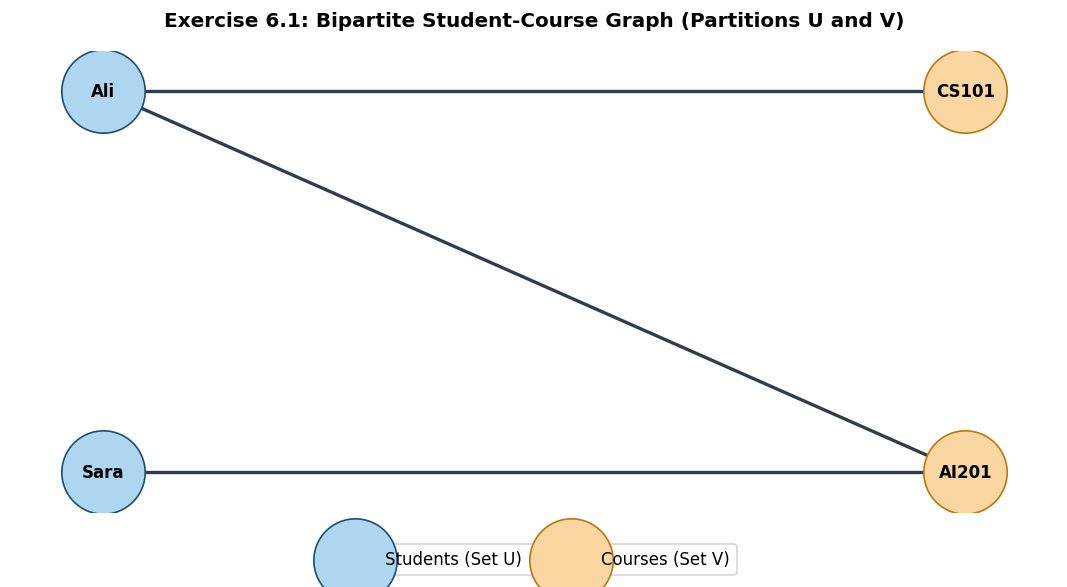

In [8]:
# Initialize Student-Course Bipartite Graph
B = nx.Graph()
students = {'Ali', 'Sara'}
course_set = {'CS101', 'AI201'}

B.add_nodes_from(students, bipartite=0)
B.add_nodes_from(course_set, bipartite=1)
B.add_edges_from([('Ali', 'CS101'), ('Sara', 'AI201'), ('Ali', 'AI201')])

print(f"Is Student/Course graph B bipartite? {nx.is_bipartite(B)}")

# Exercise 6.1: Draw B with students on the left and courses on the right
pos_b = nx.bipartite_layout(B, students)

plt.figure(figsize=(9, 5))
nx.draw_networkx_nodes(B, pos_b, nodelist=list(students), node_color='#AED6F1', node_size=2500, edgecolors='#1B4F72', label='Students (Set U)')
nx.draw_networkx_nodes(B, pos_b, nodelist=list(course_set), node_color='#FAD7A0', node_size=2500, edgecolors='#B9770E', label='Courses (Set V)')
nx.draw_networkx_edges(B, pos_b, width=2, edge_color='#2C3E50')
nx.draw_networkx_labels(B, pos_b, font_size=10, font_weight='bold')

plt.title("Exercise 6.1: Bipartite Student-Course Graph (Partitions U and V)", fontsize=12, fontweight='bold', pad=15)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()

Exercise 6.2: Graph Bipartiteness Verification:
  1. Simple Square (A-B-C-D-A):       is_bipartite = True
  2. Square with diagonal (A-C):       is_bipartite = False
  3. Triangle (A-B-C-A):               is_bipartite = False


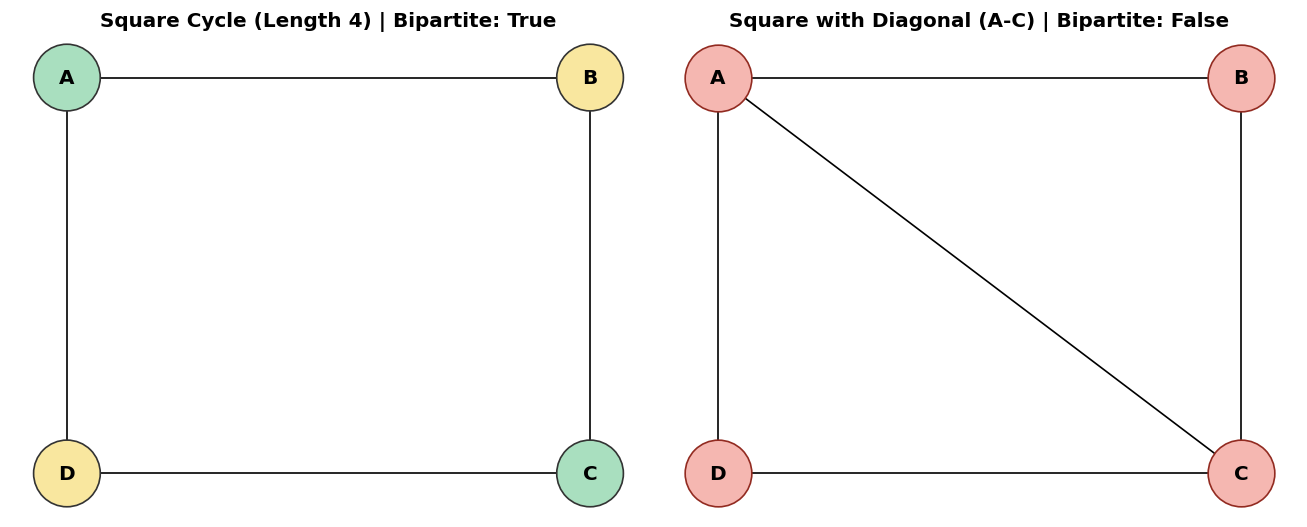

In [9]:
# Exercise 6.2: Verify the square A-B-C-D-A and square with diagonal A-C

# Graph 1: Simple 4-cycle square (A - B - C - D - A)
Square = nx.Graph([('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'A')])

# Graph 2: Square with diagonal A-C
Square_diag = nx.Graph([('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'A'), ('A', 'C')])

# Graph 3: Triangle T from manual
T = nx.Graph([('A', 'B'), ('B', 'C'), ('C', 'A')])

is_sq_bip = nx.is_bipartite(Square)
is_diag_bip = nx.is_bipartite(Square_diag)
is_tri_bip = nx.is_bipartite(T)

print("Exercise 6.2: Graph Bipartiteness Verification:")
print(f"  1. Simple Square (A-B-C-D-A):       is_bipartite = {is_sq_bip}")
print(f"  2. Square with diagonal (A-C):       is_bipartite = {is_diag_bip}")
print(f"  3. Triangle (A-B-C-A):               is_bipartite = {is_tri_bip}")

# Visualization of Square vs. Square with Diagonal
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

pos_sq = {'A': (-1, 1), 'B': (1, 1), 'C': (1, -1), 'D': (-1, -1)}

# Plot 1: Square
axes[0].set_title(f"Square Cycle (Length 4) | Bipartite: {is_sq_bip}", fontweight='bold')
colors_sq = ['#A9DFBF' if n in ['A', 'C'] else '#F9E79F' for n in Square.nodes()]
nx.draw_networkx(Square, pos_sq, ax=axes[0], node_color=colors_sq, node_size=1600, edgecolors='#333333', font_weight='bold')
axes[0].axis('off')

# Plot 2: Square with Diagonal
axes[1].set_title(f"Square with Diagonal (A-C) | Bipartite: {is_diag_bip}", fontweight='bold')
nx.draw_networkx(Square_diag, pos_sq, ax=axes[1], node_color='#F5B7B1', node_size=1600, edgecolors='#922B21', font_weight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Task 6 — Exercise 6.2: Explanation of Bipartiteness Results
> **Mathematical and Graph-Theoretic Rationale:**  
> 1. **Square Cycle $A–B–C–D–A$ (Bipartite = True):**  
>    The square consists of a single even cycle of length 4. Its vertices can be cleanly partitioned into two independent 2-coloring sets: $U = \{A, C\}$ and $V = \{B, D\}$. Every edge connects a vertex in $U$ to a vertex in $V$, with zero internal edges.  
> 2. **Square with Diagonal $A–C$ (Bipartite = False):**  
>    Adding the chord $(A, C)$ splits the 4-cycle into two 3-cycles (triangles: $A–B–C–A$ and $A–C–D–A$). By König's Theorem, any graph containing an **odd-length cycle** (length 3) cannot be 2-colored and therefore is **not bipartite**. If $A$ is colored Red, then $B$ must be Blue, forcing $C$ to be Red; but the edge $(A, C)$ connects two adjacent Red vertices, violating bipartiteness.

## Task 7 — Conceptual Graphs and Translation to FOL
A **Conceptual Graph (CG)** (John Sowa, 1984) is a bipartite directed graph representing logic in visual form:
- **Concept Nodes:** Drawn as rectangles, denoting entities with their types `[Type: Entity]`.
- **Conceptual Relation Nodes:** Drawn as circles, denoting predicates `(relation)`.
- **Bipartite Constraint:** Every directed edge strictly joins a concept to a relation or a relation to a concept; edges never directly connect concept-to-concept.

### Exercises:
- **Exercise 7.1:** Draw the conceptual graph with blue rectangular concepts, teal circular relations, and directional arrows.
- **Exercise 7.2:** Write the corresponding ground First-Order Logic (FOL) conjunction.
- **Exercise 7.3:** Add `[ResearchProject: AIHealthcare]` and a `works-on` relation from `Ali`. Update the FOL facts. Explain why a new universal rule cannot be inferred merely from these ground facts.

In [10]:
# Baseline Conceptual Graph Construction
CG = nx.DiGraph()
concepts = {'DrAhmed': 'Teacher', 'CS101': 'Course', 'Ali': 'Student'}

for entity, kind in concepts.items():
    CG.add_node(entity, kind='concept', label=f"[{kind}: {entity}]")

relations_cg = [
    ('r_teach', 'teaches', 'DrAhmed', 'CS101'),
    ('r_supervise', 'supervises', 'DrAhmed', 'Ali'),
    ('r_enroll', 'enrolled-in', 'Ali', 'CS101')
]

for rid, label, src, dst in relations_cg:
    CG.add_node(rid, kind='relation', label=f"({label})")
    CG.add_edge(src, rid)
    CG.add_edge(rid, dst)

# Verify Bipartite Property of Conceptual Graph
assert all(CG.nodes[u]['kind'] != CG.nodes[v]['kind'] for u, v in CG.edges()), "Error: Concept-to-Concept or Relation-to-Relation edge found!"

print("Conceptual Graph Node Classification:")
print("  Concept nodes: ", [n for n in CG if CG.nodes[n]['kind'] == 'concept'])
print("  Relation nodes:", [n for n in CG if CG.nodes[n]['kind'] == 'relation'])
print("  Bipartite assertion passed: Every edge joins unlike node types.")

Conceptual Graph Node Classification:
  Concept nodes:  ['DrAhmed', 'CS101', 'Ali']
  Relation nodes: ['r_teach', 'r_supervise', 'r_enroll']
  Bipartite assertion passed: Every edge joins unlike node types.


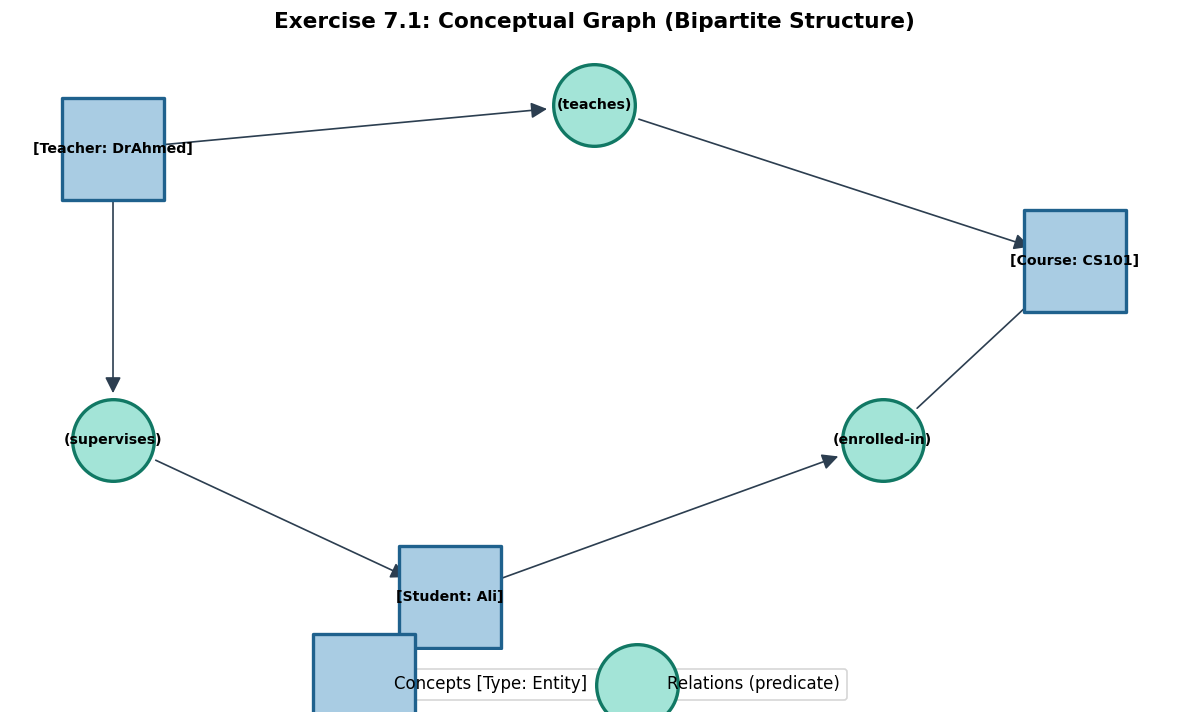

In [11]:
# Exercise 7.1: Draw Conceptual Graph with blue rectangular concepts and teal circular relations
pos_cg = {
    'DrAhmed': (-1.0, 1.0),
    'r_teach': (0.0, 1.2),
    'CS101': (1.0, 0.5),
    'r_supervise': (-1.0, -0.3),
    'Ali': (-0.3, -1.0),
    'r_enroll': (0.6, -0.3)
}

plt.figure(figsize=(10, 6))

concept_nodes = [n for n in CG if CG.nodes[n]['kind'] == 'concept']
relation_nodes = [n for n in CG if CG.nodes[n]['kind'] == 'relation']

# Blue rectangular concepts
nx.draw_networkx_nodes(
    CG, pos_cg,
    nodelist=concept_nodes,
    node_shape='s',
    node_size=3800,
    node_color='#A9CCE3',
    edgecolors='#1F618D',
    linewidths=2,
    label='Concepts [Type: Entity]'
)

# Teal circular relations
nx.draw_networkx_nodes(
    CG, pos_cg,
    nodelist=relation_nodes,
    node_shape='o',
    node_size=2400,
    node_color='#A3E4D7',
    edgecolors='#117864',
    linewidths=2,
    label='Relations (predicate)'
)

# Directional arrows
nx.draw_networkx_edges(
    CG, pos_cg,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=20,
    edge_color='#2C3E50',
    node_size=3200
)

# Labels
cg_labels = {n: CG.nodes[n]['label'] for n in CG.nodes()}
nx.draw_networkx_labels(CG, pos_cg, labels=cg_labels, font_size=8.5, font_weight='bold')

plt.title("Exercise 7.1: Conceptual Graph (Bipartite Structure)", fontsize=13, fontweight='bold', pad=15)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()

### Task 7 — Exercise 7.2: Ground First-Order Logic (FOL) Conjunction
The conceptual graph translates directly into the following Ground First-Order Logic (FOL) conjunction:

$$\text{Teacher}(\text{DrAhmed}) \land \text{Course}(\text{CS101}) \land \text{Student}(\text{Ali}) \land \text{Teaches}(\text{DrAhmed}, \text{CS101}) \land \text{Supervises}(\text{DrAhmed}, \text{Ali}) \land \text{EnrolledIn}(\text{Ali}, \text{CS101})$$

> **Formal Mapping Principles:**
> 1. Each concept box $[T : c]$ translates to a unary type predicate: $T(c)$.
> 2. Each relation circle $(R)$ with incoming arrow from concept $c_1$ and outgoing arrow to concept $c_2$ translates to a binary relation predicate: $R(c_1, c_2)$.
> 3. The entire graph represents an assertion of all its elements existing simultaneously, conjoined via logical conjunction ($\land$).

In [12]:
# Exercise 7.3: Add [ResearchProject: AIHealthcare] and 'works-on' relation from Ali
CG_extended = CG.copy()

# Add new concept node
CG_extended.add_node('AIHealthcare', kind='concept', label='[ResearchProject: AIHealthcare]')

# Add new relation node and edges
CG_extended.add_node('r_works_on', kind='relation', label='(works-on)')
CG_extended.add_edge('Ali', 'r_works_on')
CG_extended.add_edge('r_works_on', 'AIHealthcare')

# Verify bipartite property remains intact
assert all(CG_extended.nodes[u]['kind'] != CG_extended.nodes[v]['kind'] for u, v in CG_extended.edges())

print("Exercise 7.3: Extended Conceptual Graph:")
print(f"  Total nodes: {CG_extended.number_of_nodes()} ({[n for n in CG_extended.nodes()]})")
print(f"  Total edges: {CG_extended.number_of_edges()}")
print(f"  Bipartite integrity preserved: {all(CG_extended.nodes[u]['kind'] != CG_extended.nodes[v]['kind'] for u, v in CG_extended.edges())}")

# Print ground FOL formula
fol_ground_facts = [
    "Teacher(DrAhmed)",
    "Course(CS101)",
    "Student(Ali)",
    "ResearchProject(AIHealthcare)",
    "Teaches(DrAhmed, CS101)",
    "Supervises(DrAhmed, Ali)",
    "EnrolledIn(Ali, CS101)",
    "WorksOn(Ali, AIHealthcare)"
]

fol_formula = " ∧ ".join(fol_ground_facts)
print("-" * 60)
print("Updated Ground FOL Conjunction:")
print(f"  {fol_formula}")

Exercise 7.3: Extended Conceptual Graph:
  Total nodes: 8 (['DrAhmed', 'CS101', 'Ali', 'r_teach', 'r_supervise', 'r_enroll', 'AIHealthcare', 'r_works_on'])
  Total edges: 8
  Bipartite integrity preserved: True
------------------------------------------------------------
Updated Ground FOL Conjunction:
  Teacher(DrAhmed) ∧ Course(CS101) ∧ Student(Ali) ∧ ResearchProject(AIHealthcare) ∧ Teaches(DrAhmed, CS101) ∧ Supervises(DrAhmed, Ali) ∧ EnrolledIn(Ali, CS101) ∧ WorksOn(Ali, AIHealthcare)


### Task 7 — Exercise 7.3: Why Universal Rules Cannot Be Inferred Merely from Ground Facts
> **Logical and Philosophical Justification:**  
> Ground facts are specific empirical observations holding for designated individuals in a particular state of affairs (existential model instantiation).  
> In formal deductive logic, **particular statements do not imply universal generalizations**:  
> $$\{\text{Student}(\text{Ali}), \text{EnrolledIn}(\text{Ali}, \text{CS101}), \text{WorksOn}(\text{Ali}, \text{AIHealthcare})\} \not\models \forall x \ [(\text{Student}(x) \land \text{EnrolledIn}(x, \text{CS101})) \to \text{WorksOn}(x, \text{AIHealthcare})]$$  
> 
> Inferring a universally quantified rule from specific ground facts constitutes **Inductive Generalization**, which is inherently unsound in deductive logic. There may exist another student (e.g., `Sara`) who is enrolled in `CS101` but works on robotics or does not participate in any research project. Ground facts confirm what *is* true for specific entities; universal rules dictate what *must* hold for *all* possible entities.

## Task 8 — Integrated Mini-Project and Checks
We integrate all representations into a unified, reusable University Knowledge System and run the complete verification suite across Checks 1–6.

In [13]:
print("=" * 70)
print("EE348 KRR LAB 6: INTEGRATED REASONING REPORT & VERIFICATION SUITE")
print("=" * 70)

# Check 1: Semantic Network Queries
c1_ali_cs101 = has_relation('Ali', 'enrolled-in', 'CS101')
c1_sara_cs101 = has_relation('Sara', 'enrolled-in', 'CS101')
print("CHECK 1: Semantic Network Queries")
print(f"  - Is Ali enrolled in CS101?  --> {c1_ali_cs101} [PASSED]")
print(f"  - Is Sara enrolled in CS101? --> {c1_sara_cs101} [PASSED]")

# Check 2: Frames Inheritance & Explicit Overrides
c2_ali_status = lookup('Ali', 'status')
c2_drahmed_role = lookup('DrAhmed', 'role')
print("\nCHECK 2: Frame Inheritance & Local Overrides")
print(f"  - Ali's status after explicit override: '{c2_ali_status}' [PASSED]")
print(f"  - DrAhmed's inherited role from Teacher: '{c2_drahmed_role}' [PASSED]")

# Check 3: Inheritance Conflict Resolution
c3_ta_resolved = resolve_multiple(['Student', 'Employee'], 'receives_salary', explicit=True)
c3_ta_unresolved = resolve_multiple(['Student', 'Employee'], 'receives_salary', explicit=None)
print("\nCHECK 3: Inheritance Conflict Disambiguation")
print(f"  - Without policy override: '{c3_ta_unresolved}' detected [PASSED]")
print(f"  - With explicit policy override: receives_salary = {c3_ta_resolved} [PASSED]")

# Check 4: Scripts Execution (Success & Failure)
c4_pass = run_script({'eligible_student': True, 'registration_open': True, 'payment_cleared': True}, reg_script_payment)
c4_fail = run_script({'eligible_student': True, 'registration_open': True, 'payment_cleared': False}, reg_script_payment)
print("\nCHECK 4: Script Execution Engine")
print(f"  - Successful Registration Trace: {c4_pass[-1]} ({len(c4_pass)-1} scenes executed) [PASSED]")
print(f"  - Failed Registration Output:   {c4_fail[0]} [PASSED]")

# Check 5: Graph Bipartiteness
c5_b_bipartite = nx.is_bipartite(B)
c5_t_bipartite = nx.is_bipartite(T)
print("\nCHECK 5: Graph Bipartiteness Verification")
print(f"  - Student-Course Graph Bipartite? {c5_b_bipartite} [PASSED]")
print(f"  - Triangle Graph Bipartite?       {c5_t_bipartite} (Odd cycle detected) [PASSED]")

# Check 6: Conceptual Graph Bipartite Structure & FOL Facts
c6_bipartite_cg = all(CG_extended.nodes[u]['kind'] != CG_extended.nodes[v]['kind'] for u, v in CG_extended.edges())
print("\nCHECK 6: Conceptual Graph Bipartiteness & Ground FOL Mapping")
print(f"  - Every edge joins unlike node types (Concept <-> Relation): {c6_bipartite_cg} [PASSED]")
print(f"  - Translated Ground FOL Conjunction:")
print(f"    {fol_formula}")
print("=" * 70)
print("ALL SYSTEM CHECKS COMPLETED AND VERIFIED SUCCESSFULLY!")
print("=" * 70)

EE348 KRR LAB 6: INTEGRATED REASONING REPORT & VERIFICATION SUITE
CHECK 1: Semantic Network Queries
  - Is Ali enrolled in CS101?  --> True [PASSED]
  - Is Sara enrolled in CS101? --> False [PASSED]

CHECK 2: Frame Inheritance & Local Overrides
  - Ali's status after explicit override: 'Graduated' [PASSED]
  - DrAhmed's inherited role from Teacher: 'Instructor' [PASSED]

CHECK 3: Inheritance Conflict Disambiguation
  - Without policy override: 'CONFLICT' detected [PASSED]
  - With explicit policy override: receives_salary = True [PASSED]

CHECK 4: Script Execution Engine
  - Successful Registration Trace: registered (6 scenes executed) [PASSED]
  - Failed Registration Output:   STOP: entry condition failed (payment_cleared) [PASSED]

CHECK 5: Graph Bipartiteness Verification
  - Student-Course Graph Bipartite? True [PASSED]
  - Triangle Graph Bipartite?       False (Odd cycle detected) [PASSED]

CHECK 6: Conceptual Graph Bipartiteness & Ground FOL Mapping
  - Every edge joins unlike no

## Challenge (Optional): Taxonomic Path Traversal
We implement `instance_of_class(instance, target_class)` that follows an `instance-of` link followed by zero or more `is-a` links to test class subsumption membership (e.g., testing whether `Ali` is a `Person`).

### Exercise:
- Test queries: `instance_of_class('Ali', 'Person')`, `instance_of_class('Ali', 'Student')`, `instance_of_class('DrAhmed', 'Person')`, and `instance_of_class('Ali', 'Teacher')`.
- Explain why traversing `enrolled-in` would not be appropriate for class inheritance.

In [14]:
def instance_of_class(instance, target_class, rels=relations):
    # Determines whether an instance belongs to target_class by:
    # 1. Finding the immediate class C where (instance, 'instance-of', C) holds.
    # 2. Traversing zero or more (C, 'is-a', Parent) links to reach target_class.
    # Step 1: Find direct class of the instance
    direct_classes = [tgt for src, rel, tgt in rels if src == instance and rel == 'instance-of']
    if not direct_classes:
        return False
    
    # Step 2: Breadth-First Search along 'is-a' edges
    queue = list(direct_classes)
    visited = set(direct_classes)
    
    while queue:
        current_class = queue.pop(0)
        if current_class == target_class:
            return True
        # Find parent classes via 'is-a'
        for src, rel, tgt in rels:
            if src == current_class and rel == 'is-a' and tgt not in visited:
                visited.add(tgt)
                queue.append(tgt)
                
    return False

# Test Challenge queries
challenge_tests = [
    ("Ali", "Person", True),
    ("Ali", "Student", True),
    ("DrAhmed", "Person", True),
    ("DrAhmed", "Teacher", True),
    ("Ali", "Teacher", False),
    ("DrAhmed", "Student", False)
]

print("Challenge Solution: Testing instance_of_class:")
for inst, target_cls, expected in challenge_tests:
    result = instance_of_class(inst, target_cls)
    status = "CORRECT" if result == expected else "INCORRECT"
    print(f"  instance_of_class('{inst}', '{target_cls}') -> {result} (Expected: {expected}) [{status}]")

Challenge Solution: Testing instance_of_class:
  instance_of_class('Ali', 'Person') -> True (Expected: True) [CORRECT]
  instance_of_class('Ali', 'Student') -> True (Expected: True) [CORRECT]
  instance_of_class('DrAhmed', 'Person') -> True (Expected: True) [CORRECT]
  instance_of_class('DrAhmed', 'Teacher') -> True (Expected: True) [CORRECT]
  instance_of_class('Ali', 'Teacher') -> False (Expected: False) [CORRECT]
  instance_of_class('DrAhmed', 'Student') -> False (Expected: False) [CORRECT]


### Challenge Explanation: Why Traversing `enrolled-in` Violates Inheritance Semantics
> **Ontological Distinction Between Subsumption and Association:**  
> - **`is-a` (Subsumption / Specialization):** Represents taxonomic set inclusion ($A \subseteq B$). It satisfies monotonic transitivity and property inheritance: if $x$ is a `Student` and `Student` is a `Person`, then every essential property of `Person` is necessarily true of $x$.  
> - **`enrolled-in` (Contingent Association):** Represents an episodic, non-taxonomic domain relation between an autonomous agent and an educational curriculum ($x \in \text{CourseParticipants}(y)$).  
> 
> If an inheritance reasoner improperly traversed `enrolled-in` links as if they were inheritance links, `Ali` would inherit all slot definitions, attributes, and constraints of `CS101` (such as `credit_hours: 3`, `prerequisite: 'None'`, `course_code: 'CS101'`). This causes a severe **category mistake** (Ryle, 1949), falsely asserting that a human being has 3 credit hours and a syllabus.

## Post-Lab Discussion & Comparative Analysis

### Comparative Synthesis of Structural Representations
| Representation Formalism | Core Semantic Structure | Primary Reasoning Mechanism | Key Strengths | Inherent Limitations |
| :--- | :--- | :--- | :--- | :--- |
| **Semantic Networks** | Directed labeled graph of concepts and associative edges | Graph search, path checking, spreading activation | Visually intuitive, flexible associative search | Lacks standard formal semantics; relation meanings are ad-hoc |
| **Frames & Slots** | Record structures with slots, fillers, and defaults | Hierarchical inheritance with default overrides | Compact representation of prototypical defaults | Conflict ambiguity in multiple inheritance (diamond problem) |
| **Scripts** | Rigid episodic event sequences with roles and scenes | Sequential schema instantiation and scene tracing | Excellent for default expectation and narrative comprehension | Inflexible to unexpected event re-ordering or dynamic exceptions |
| **Bipartite Graphs** | 2-partitioned graph with edges only between disjoint sets | 2-colorability check, odd cycle detection (König) | Clean conceptual isolation between distinct ontological realms | Restricted edge topology; cannot model intra-set relationships |
| **Conceptual Graphs** | Bipartite graph of concepts (boxes) and relations (circles) | Graph homomorphism, canonical formation, FOL translation | Precise formal semantics bridging graphs and First-Order Logic | Higher expressive constructs require complex nested contexts |

### Summary & Conclusion
In this lab, we successfully designed, implemented, and queried all primary structural knowledge representation formalisms in Python:
1. Built a directed semantic network using `NetworkX` and demonstrated that edge direction is essential for preserving asymmetric binary predicate roles.
2. Implemented frame hierarchies with default slot inheritance, showing that instance overrides protect prototype classes from unintended side effects.
3. Diagnosed and resolved multiple inheritance conflicts (the diamond problem) using explicit disambiguation rules.
4. Simulated real-world episodic processes via scripts, showing why rigid sequential scripts break under out-of-order events.
5. Verified graph bipartiteness using König's theorem, contrasting bipartite structures with odd-cycle triangles.
6. Modeled a conceptual graph as a bipartite directed structure, verified its topological constraints, translated it directly into Ground First-Order Logic facts, and demonstrated why inductive generalizations cannot be deduced from ground assertions alone.